# 04 · KNN held-out evaluation

This notebook loads the saved KNN pipeline and evaluates it once on the untouched stratified test partition. **It does not fit or retrain a model.** It recreates the split using the same seed and stratification recipe as Notebook 3, then checks the loaded artifact before calculating test metrics.

**Primary metric:** malignant-class recall. Secondary metrics: precision, F1, specificity, accuracy, balanced accuracy, and ROC-AUC. These results estimate performance on this held-out partition only and do not establish clinical readiness or external generalization.

In [1]:
from pathlib import Path
import json
import math
from statistics import NormalDist

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split

SEED = 42
TARGET = 'diagnosis'
ID_COLUMN = 'id'
LABEL_TO_INT = {'B': 0, 'M': 1}
POSITIVE_LABEL = 1
cwd = Path.cwd().resolve()
REPO_ROOT = next((candidate for candidate in [cwd, *cwd.parents]
                  if (candidate / 'data/raw/Raw_Breast_Cancer_Data.csv').exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate repository data/raw/Raw_Breast_Cancer_Data.csv from the notebook working directory.')
DATA_PATH = REPO_ROOT / 'data/raw/Raw_Breast_Cancer_Data.csv'
MODEL_DIR = REPO_ROOT / 'models/KNN'
REPORT_DIR = REPO_ROOT / 'reports/figures/KNN'
MODEL_PATH = MODEL_DIR / 'knn_pipeline.joblib'
METADATA_PATH = REPORT_DIR / 'model_metadata.json'
print(f'Python package environment: scikit-learn {sklearn.__version__}')
print('Model artifact:', MODEL_PATH)

Python package environment: scikit-learn 1.9.0
Model artifact: C:\Projects_Tracking\Breast_Cancer_Prediction\models\KNN\knn_pipeline.joblib


In [2]:
if not MODEL_PATH.exists() or not METADATA_PATH.exists():
    raise FileNotFoundError('Run KNN Notebook 3 first and confirm its pipeline and metadata artifacts are present.')
metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
if metadata.get('model') != 'KNeighborsClassifier':
    raise ValueError('The metadata does not describe the expected KNN model.')
if metadata.get('seed') != SEED or metadata.get('target') != TARGET:
    raise ValueError('Notebook 3 metadata does not match the expected target or split seed.')

raw_df = pd.read_csv(DATA_PATH)
empty_columns = raw_df.columns[raw_df.isna().all()].tolist()
df = raw_df.drop(columns=empty_columns).copy()
y = df[TARGET].map(LABEL_TO_INT)
if y.isna().any() or set(y.unique()) != {0, 1}:
    raise ValueError('Unexpected target labels; stop and inspect the dataset.')
feature_names = metadata['features']
if feature_names != [c for c in df.columns if c not in [TARGET, ID_COLUMN]]:
    raise ValueError('Dataset feature columns/order differ from model metadata.')
X = df[feature_names]

# Reproduce Notebook 3's exact 60/20/20 partitions; no fitting occurs here.
all_idx = np.arange(len(y))
dev_idx, test_idx = train_test_split(
    all_idx, test_size=0.20, random_state=SEED, stratify=y)
train_idx, val_idx = train_test_split(
    dev_idx, test_size=0.25, random_state=SEED, stratify=y.iloc[dev_idx])
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
print(f'Test records: {len(test_idx)}')
print('Test class counts:', y_test.value_counts().sort_index().rename(index={0: 'B (benign)', 1: 'M (malignant)'}).to_dict())
print('Test partition matches saved metadata:', len(test_idx) == metadata['split_sizes']['test'])

Test records: 114
Test class counts: {'B (benign)': 72, 'M (malignant)': 42}
Test partition matches saved metadata: True


In [3]:
# Load-only sanity check. This notebook contains no fit() or fit_transform() call.
model = joblib.load(MODEL_PATH)
if not hasattr(model, 'predict') or not hasattr(model, 'predict_proba'):
    raise TypeError('Loaded artifact is not a prediction pipeline with probability support.')
if list(model.feature_names_in_) != feature_names:
    raise ValueError('Loaded model feature order differs from metadata.')
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, list(model.classes_).index(POSITIVE_LABEL)]
if len(y_pred) != len(y_test) or not np.isfinite(y_score).all():
    raise ValueError('Loaded model did not produce valid predictions for every test row.')
print('Load and prediction sanity check passed.')
print('Predictions:', len(y_pred), '| positive-class probability range:',
      (round(float(y_score.min()), 4), round(float(y_score.max()), 4)))

Load and prediction sanity check passed.
Predictions: 114 | positive-class probability range: (0.0, 1.0)


## Held-out test metrics

The positive class is malignant (`M`, encoded as 1). Specificity is the fraction of benign cases correctly identified. The Wilson 95% interval for malignant recall displays sampling uncertainty for the test partition's malignant cases; it does not account for dataset shift.

,held-out test result
malignant_recall (primary),0.904762
precision,0.974359
F1,0.938272
specificity,0.986111
accuracy,0.956140
balanced_accuracy,0.945437
ROC-AUC,0.982308
true_negatives,71.000000
false_positives,1.000000
false_negatives,4.000000


Classification report (0=benign, 1=malignant):
               precision    recall  f1-score   support

   Benign (B)       0.95      0.99      0.97        72
Malignant (M)       0.97      0.90      0.94        42

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 weighted avg       0.96      0.96      0.96       114



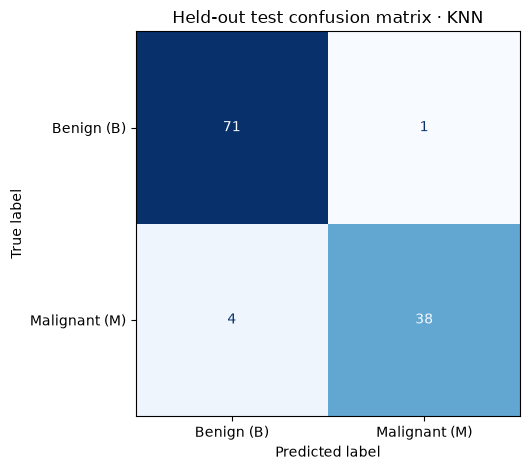

In [4]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
test_metrics = {
    'malignant_recall (primary)': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    'precision': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    'F1': f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    'specificity': tn / (tn + fp) if (tn + fp) else np.nan,
    'accuracy': accuracy_score(y_test, y_pred),
    'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_score),
    'true_negatives': int(tn), 'false_positives': int(fp),
    'false_negatives': int(fn), 'true_positives': int(tp),
}

def wilson_interval(successes, trials, confidence=0.95):
    if trials == 0:
        return (np.nan, np.nan)
    z = NormalDist().inv_cdf(1 - (1 - confidence) / 2)
    p_hat = successes / trials
    denom = 1 + z*z/trials
    center = (p_hat + z*z/(2*trials)) / denom
    half = z * math.sqrt(p_hat*(1-p_hat)/trials + z*z/(4*trials*trials)) / denom
    return center-half, center+half

recall_ci = wilson_interval(tp, tp + fn)
test_metrics['malignant_recall_Wilson_95%_low'] = recall_ci[0]
test_metrics['malignant_recall_Wilson_95%_high'] = recall_ci[1]
display(pd.Series(test_metrics, name='held-out test result').to_frame())
print('Classification report (0=benign, 1=malignant):')
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['Benign (B)', 'Malignant (M)'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['Benign (B)', 'Malignant (M)'],
    cmap='Blues', colorbar=False)
plt.title('Held-out test confusion matrix · KNN')
plt.tight_layout()
plt.show()

## Error analysis

Review false negatives first because malignant recall is the primary metric. The source record ID is shown only for error identification; it is excluded from the model inputs. Predicted probabilities are KNN vote fractions, not calibrated clinical risk estimates.

In [5]:
test_results = pd.DataFrame({
    'source_id': df.iloc[test_idx][ID_COLUMN].to_numpy(),
    'actual': pd.Series(y_test.to_numpy()).map({0: 'B', 1: 'M'}),
    'predicted': pd.Series(y_pred).map({0: 'B', 1: 'M'}),
    'malignant_probability': y_score,
})
test_results['error_type'] = np.select(
    [(test_results.actual == 'M') & (test_results.predicted == 'B'),
     (test_results.actual == 'B') & (test_results.predicted == 'M')],
    ['false_negative', 'false_positive'], default='correct')
errors = test_results[test_results.error_type != 'correct'].sort_values('malignant_probability')
print('Test error counts:', test_results.error_type.value_counts().to_dict())
print('Misclassified test records:')
display(errors.reset_index(drop=True))

Test error counts: {'correct': 109, 'false_negative': 4, 'false_positive': 1}
Misclassified test records:


,source_id,actual,predicted,malignant_probability,error_type
0,859983,M,B,0.0,false_negative
1,862548,M,B,0.2,false_negative
2,90291,M,B,0.2,false_negative
3,879523,M,B,0.2,false_negative
4,8810158,B,M,0.6,false_positive


## Test results, comparison, limitations, and conclusion

The loaded KNN pipeline passed the prediction sanity check and evaluated **114 held-out records** (72 benign, 42 malignant) without retraining. It produced **0.9048 malignant recall** (38/42), **0.9744 precision**, **0.9383 F1**, **0.9861 specificity**, **0.9561 accuracy**, **0.9454 balanced accuracy**, and **0.9823 ROC-AUC**. The confusion matrix had 71 true negatives, 1 false positive, 4 false negatives, and 38 true positives. The Wilson 95% interval for malignant recall is **0.7793–0.9623**, showing substantial uncertainty with only 42 malignant test cases.

The test error table reports four false negatives (source IDs `859983`, `862548`, `90291`, and `879523`) and one false positive (`8810158`). KNN's probability values are vote fractions, not calibrated clinical risk estimates.

On this same held-out split, the Logistic Regression pipeline had recall 0.9762, precision 1.0000, F1 0.9880, specificity 1.0000, accuracy 0.9912, balanced accuracy 0.9881, and ROC-AUC 0.9977. KNN therefore had lower scores on this split and three more false negatives. This is a descriptive comparison on one test set, not evidence about performance on external populations. KNN's validation recall was 0.9302, so its test recall was lower by about 0.0255.

**Conclusion:** KNN performed reasonably on this test partition, but under the predeclared malignant-recall priority it underperformed Logistic Regression on the shared split, especially in missed malignant cases. For this dataset and split, Logistic Regression is the stronger candidate. Neither model is clinically validated or proven to generalize beyond this source.

**Limitations:** the 114-record test partition contains only 42 malignant cases, making recall sensitive to a few cases; its confidence interval is wide. All splits come from the same curated dataset, with no independent hospital, acquisition-site, demographic, or clinical context to assess distribution shift or subgroup performance. KNN is sensitive to scaling, neighbor choice, correlated predictors, and local sample density. Its vote fractions are not calibrated risk scores. No feature- or model-level conclusion here should be presented as diagnostic guidance.

### Self-critique

The strongest objection is that Logistic Regression's higher scores on one shared split may not persist on a new cohort, while KNN's four false negatives make it less suitable under the project's recall-first objective on this sample. The small test set and wide recall interval limit both conclusions. We report the same-split comparison and individual errors but cannot resolve external generalization without independent data.